<a href="https://colab.research.google.com/github/ogbudu/altexamnew/blob/main/marketingdataanalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***Group number**: 25
**Full name**: Timothy Ogbudu
**Dataset**: Bank Marketing (Term Deposit)
**Depth Track**:
**Team members**: Solo
**Final model**: Random Forest Classifier(Baseline)
**Stratified dummy F1 / ROC AUC**: 0.472/0.495
**Final model F1 / ROC AUC**: 0.681/0.757
**Leakage columns dropped**: "duration"
**Full run time on Colab**: 1 minute

# Part 1: Data Foundation


In [1]:
!pip install kagglehub -q



In [2]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3


In [3]:
path = kagglehub.dataset_download("janiobachmann/bank-marketing-dataset")
csv_file_path = os.path.join(path, "bank.csv")

Using Colab cache for faster access to the 'bank-marketing-dataset' dataset.


In [4]:
df = pd.read_csv(csv_file_path)

In [5]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [6]:
df.shape

(11162, 17)

In [7]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [11]:
df['pdays'].value_counts()

,count
pdays,
-1,8324
92,106
182,89
91,84
181,81
...,...
717,1
159,1
118,1


In [12]:
df['deposit'].value_counts()

,count
deposit,
no,5873
yes,5289


From the above result, the data seems not to be balanced

This is a marketing data depicting the result of the last marketing carried out by the team and how effective it was.The result of this campaign was that either the customer ended up depositing or not. In this first part of data exploration, I would be looking at it in the following perspective:
1. What is the relationship between all the numerical variables?
2. What are the effects of the numerical variables on the outcome(deposit- either yes or no).
3. What are the age groups in the data
4. What are the job categories of customers in the data
5. What is the relationship between age and balance, job type and balance, job type and deposit, call duration and deposit e.t.c.

Text(0, 0.5, 'Frequency')

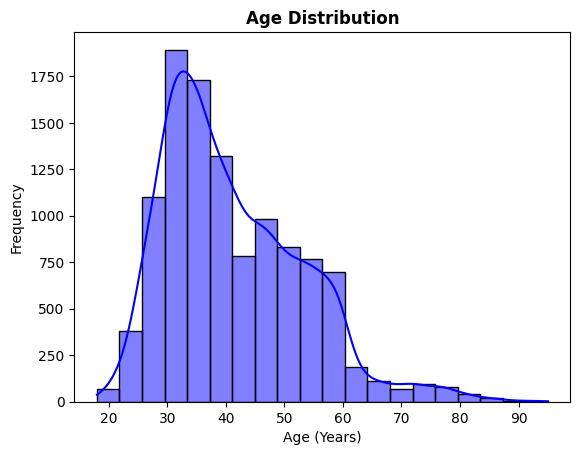

In [13]:
fig, ax = plt.subplots(1, 1)
sns.histplot(df['age'], kde=True, color='blue', ax=ax, bins=20)
ax.set_title('Age Distribution', fontweight='bold')
ax.set_xlabel('Age (Years)')
ax.set_ylabel('Frequency')

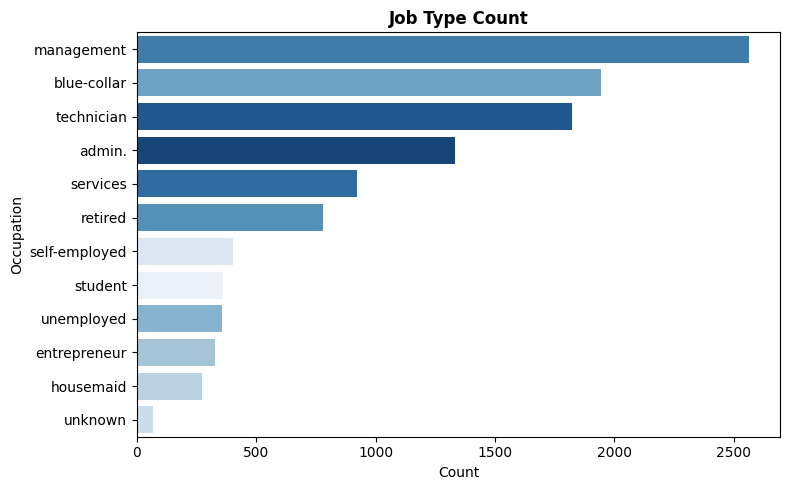

In [14]:
fig, axes = plt.subplots(figsize=(8, 5))
sns.countplot(y='job', data=df, ax=axes, palette='Blues_r', order=df['job'].value_counts().index, hue='job', legend=False)
axes.set_title('Job Type Count', fontweight='bold')
axes.set_xlabel('Count')
axes.set_ylabel('Occupation')
plt.tight_layout()

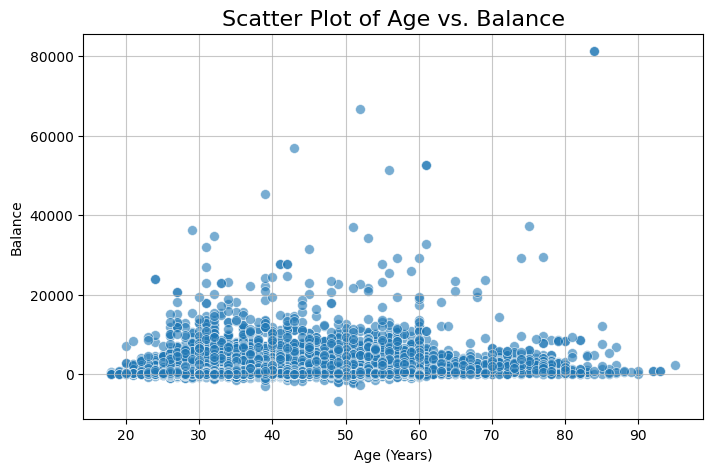

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='balance', data=df, alpha=0.6, s=50)
plt.title('Scatter Plot of Age vs. Balance', fontsize=16)
plt.xlabel('Age (Years)')
plt.ylabel('Balance')
plt.grid(True,alpha=0.7)
plt.show()

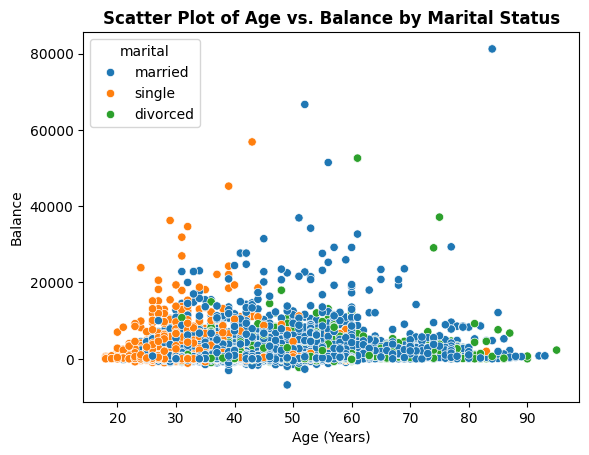

In [16]:
sns.scatterplot(data=df, x='age', y='balance', hue='marital')
plt.title('Scatter Plot of Age vs. Balance by Marital Status', fontweight='bold')
plt.xlabel('Age (Years)')
plt.ylabel('Balance')
plt.show()

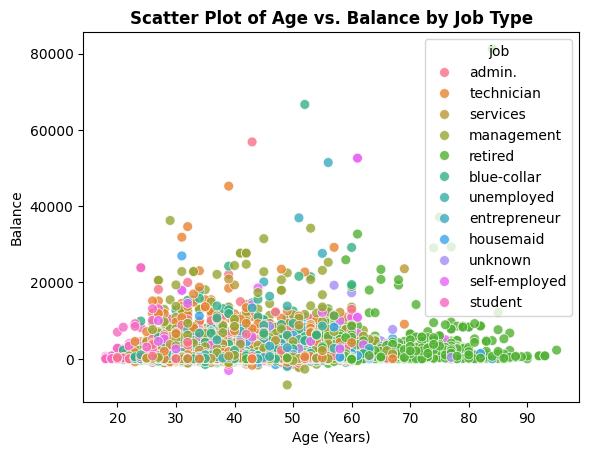

In [17]:
sns.scatterplot(data=df, x='age', y='balance', hue='job', alpha=0.8, s=50)
plt.title('Scatter Plot of Age vs. Balance by Job Type', fontweight='bold')
plt.xlabel('Age (Years)')
plt.ylabel('Balance')
plt.show()

In [18]:
highest_balance_job = df.loc[df['balance'].idxmax(), 'job']
print(highest_balance_job)

retired


In [19]:
df[['job', 'balance']].sort_values(by='balance', ascending=False).head(5)

,job,balance
3043,retired,81204
3380,retired,81204
8208,blue-collar,66653
10143,admin.,56831
2468,self-employed,52587


The above findings tells us that the retired customers had the highest balance and should most likely be targeted for deposit during the campaign

In [20]:
avg_balance_by_job = df.groupby('job')['balance'].mean().sort_values(ascending=False)
display(avg_balance_by_job)

,balance
job,
retired,2417.250643
unknown,1945.457143
self-employed,1865.372840
management,1793.663679
entrepreneur,1621.942073
technician,1556.294569
student,1500.783333
housemaid,1366.160584
unemployed,1314.719888


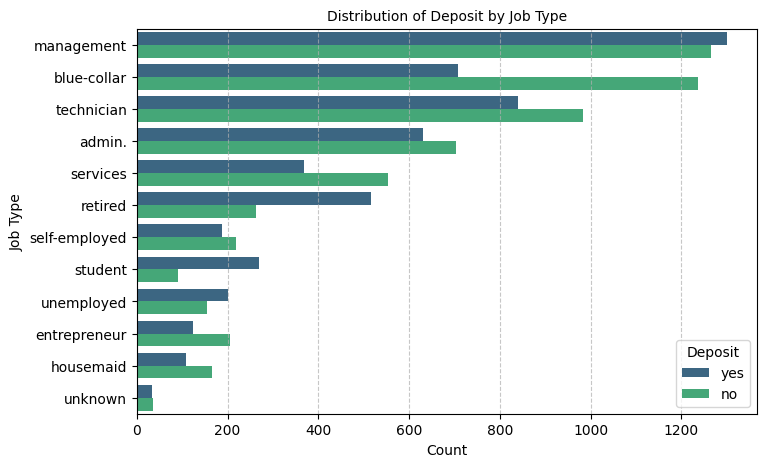

In [21]:
plt.figure(figsize=(8, 5))
sns.countplot(y='job', hue='deposit', data=df, palette='viridis', order=df['job'].value_counts().index)
plt.title('Distribution of Deposit by Job Type', fontsize=10)
plt.xlabel('Count')
plt.ylabel('Job Type')
plt.legend(title='Deposit')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

The chart above breaks down all the job type present in the dataset and also tells us how many individuals from each category deposited(yes) and did not deposit(no)

In [22]:
avg_age_by_deposit = df.groupby('deposit')['age'].mean()
display(avg_age_by_deposit)

,age
deposit,
no,40.837391
yes,41.670070


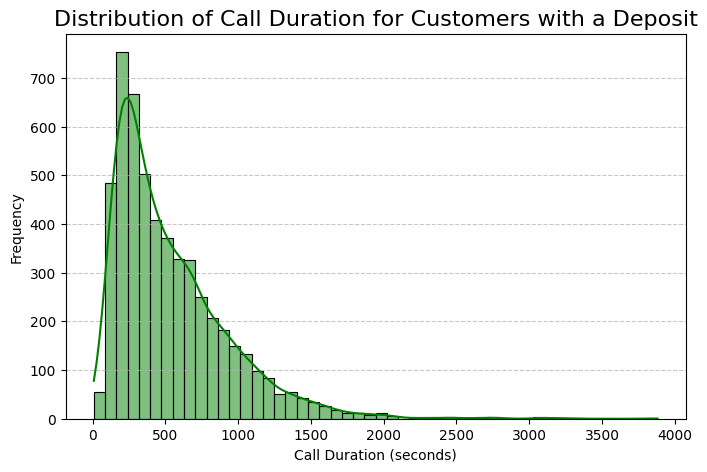

In [23]:
deposit_customers = df[df['deposit'] == 'yes']
plt.figure(figsize=(8, 5))
sns.histplot(deposit_customers['duration'], kde=True, color='green', bins=50)
plt.title('Distribution of Call Duration for Customers with a Deposit', fontsize=16)
plt.xlabel('Call Duration (seconds)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In the histplot above, we can see that call duration that led to the most deposits peaked at 500 seconds and then dradually began to see a drp in deposit rate as the time of call increased significantly.. We can deduce from here that and increased cal duration led to the client depositing but as the duration becomes too long, the chances of a client saying yes reduced(These set of clients are harder to concince). If you have to spend so long on the call convincing a client, then that client probably does not want that product.

In [24]:
df['deposit_numeric'] = df['deposit'].map({'yes': 1, 'no': 0})
correlation_duration_deposit = df['duration'].corr(df['deposit_numeric'])

print(f"Correlation between 'duration' and 'deposit' status: {correlation_duration_deposit:.4f}")

Correlation between 'duration' and 'deposit' status: 0.4519


In [25]:
numerical_cols = df.select_dtypes(include=np.number).columns
correlation_matrix = df[numerical_cols].corr()
correlation_matrix

,age,balance,day,duration,campaign,pdays,previous,deposit_numeric
age,1.000000,0.112300,-0.000762,0.000189,-0.005278,0.002774,0.020169,0.034901
balance,0.112300,1.000000,0.010467,0.022436,-0.013894,0.017411,0.030805,0.081129
day,-0.000762,0.010467,1.000000,-0.018511,0.137007,-0.077232,-0.058981,-0.056326
duration,0.000189,0.022436,-0.018511,1.000000,-0.041557,-0.027392,-0.026716,0.451919
campaign,-0.005278,-0.013894,0.137007,-0.041557,1.000000,-0.102726,-0.049699,-0.128081
pdays,0.002774,0.017411,-0.077232,-0.027392,-0.102726,1.000000,0.507272,0.151593
previous,0.020169,0.030805,-0.058981,-0.026716,-0.049699,0.507272,1.000000,0.139867
deposit_numeric,0.034901,0.081129,-0.056326,0.451919,-0.128081,0.151593,0.139867,1.000000


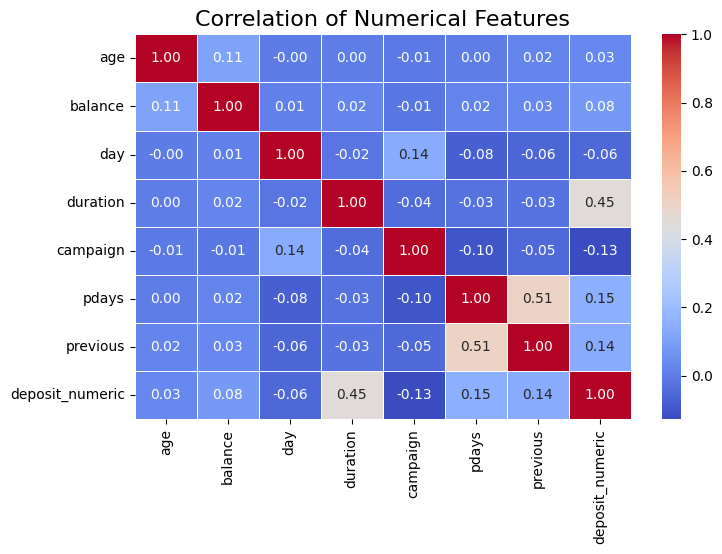

In [26]:
numerical_cols = df.select_dtypes(include=np.number).columns
correlation_matrix = df[numerical_cols].corr()
plt.figure(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation of Numerical Features', fontsize=16)
plt.show()

The highest correlation between the numerical figures is seen between duration of call and deposit meaning longer call might lead to a deposit most times

## Data cleaning

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
data_columns = ['job','marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'marital', 'deposit', 'pdays',]

for col in data_columns:
    print(f"Unique values in '{col}':\n{df[col].unique()}\n")

Unique values in 'job':
['admin.' 'technician' 'services' 'management' 'retired' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown' 'self-employed'
 'student']

Unique values in 'marital':
['married' 'single' 'divorced']

Unique values in 'education':
['secondary' 'tertiary' 'primary' 'unknown']

Unique values in 'default':
['no' 'yes']

Unique values in 'housing':
['yes' 'no']

Unique values in 'loan':
['no' 'yes']

Unique values in 'contact':
['unknown' 'cellular' 'telephone']

Unique values in 'month':
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

Unique values in 'poutcome':
['unknown' 'other' 'failure' 'success']

Unique values in 'marital':
['married' 'single' 'divorced']

Unique values in 'deposit':
['yes' 'no']

Unique values in 'pdays':
[ -1 166  91 147 170 150 171 126 182 110 198 174 175  27 128 100 177 167
 122 183 195 133 178  34  10 163 184 154  99  93   2 242 272  76 160  90
 196 246 238 203 268 189 267  92   9  88  85 210 257 26

In [29]:
df_duplicate = df.copy()

In [30]:
df_duplicate

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit,deposit_numeric
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes,1
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes,1
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes,1
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes,1
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no,0
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no,0
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no,0
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no,0


I will be dropping the duration feature becasue it will lead to leakage. This is because the duration of call will not be available during or at the time of prediction.
According to the heatmap above, their is a moderately positive correlation between duration of call and our target variable(deposit), meaning an increased duration
of call lead to a yes in the target, while zero duration automatically means no. If we build a model with this logic, it will assume a target value of no for every
duration value of zero(which is the reality in real life prediction as the call duration is usually not known beforehand i.e it is automatically zero).

In [31]:
df_duplicate = df_duplicate.drop(columns=['duration'])

In [32]:
df_duplicate

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,deposit,deposit_numeric
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1,-1,0,unknown,yes,1
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1,-1,0,unknown,yes,1
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1,-1,0,unknown,yes,1
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,1,-1,0,unknown,yes,1
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,2,-1,0,unknown,yes,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,1,-1,0,unknown,no,0
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,4,-1,0,unknown,no,0
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,2,-1,0,unknown,no,0
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,2,172,5,failure,no,0


I am leaving the 'unknown' value in the 'poutcome' column because it is structurally related to the 'pdays' column.
When a client has a 'pdays' value of -1, it means the client was never contacted in a previous campaign and as a result, their 'poutcome' value will be listed as 'unknown'. In this case, unknown isn't missing data rather it is most likely an indicator that this is a new client.
I will however convert the 'unknown' to 'new_customer'
Justification: It helps your model differentiate between a customer who ignored a past campaign (failure) and a customer who is completely new (new_customer).
Also it prevents your future preprocessing steps (like SimpleImputer) from replacing these fields with the most frequent value (which would distort customer history)

In [33]:
df_duplicate['poutcome'] = df_duplicate['poutcome'].replace('unknown', 'new_customer')

In [34]:
print(df_duplicate['poutcome'].value_counts())

poutcome
new_customer    8326
failure         1228
success         1071
other            537
Name: count, dtype: int64


In [35]:
print(df['job'].value_counts(dropna=False))

job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64


I will also be dropping the job rows with a value of 'unknown':
Justification: Employment status is a critical behavioral and demographic indicator for financial predictive modeling. Guessing or imputing these values would introduce unnecessary noise into the dataset. Because these 70 rows account for less than 0.6% of the total dataset, dropping them preserves complete profile integrity without significantly reducing sample size or introducing statistical bias.

In [36]:
import pandas as pd

if 'df' not in locals() or df is None:
    if 'csv_file_path' in locals():
        df = pd.read_csv(csv_file_path)
    else:
        raise NameError("csv_file_path is not defined. Cannot reload 'df'.")


if 'df_duplicate' not in locals() or df_duplicate is None:
    df_duplicate = df.copy()
    if 'duration' in df_duplicate.columns:
        df_duplicate = df_duplicate.drop(columns=['duration'])
    if 'poutcome' in df_duplicate.columns:
        df_duplicate['poutcome'] = df_duplicate['poutcome'].replace('unknown', 'new_customer')

df_duplicate['job'] = df_duplicate['job'].replace('unknown', np.nan)

In [37]:
df_duplicate = df_duplicate.dropna(subset=['job']).copy()

In [38]:
print(df_duplicate['job'].value_counts(dropna=False))

job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
Name: count, dtype: int64


In [39]:
pdays_counts = df['pdays'].value_counts()
most_frequent_value = pdays_counts.index[0]
most_frequent_count = pdays_counts.iloc[0]

In [40]:
print(f"The most frequent value in the 'pdays' column is: {most_frequent_value}")
print(f"It occurs {most_frequent_count} times.")


The most frequent value in the 'pdays' column is: -1
It occurs 8324 times.


In [41]:
df_duplicate['was_contacted_in_prev_campaign'] = (df_duplicate['pdays'] != -1).astype(int)
df_duplicate['pdays'] = df_duplicate['pdays'].replace(-1, np.nan)


In [42]:
df_duplicate[['pdays', 'was_contacted_in_prev_campaign']].head()

,pdays,was_contacted_in_prev_campaign
0,NaN,0
1,NaN,0
2,NaN,0
3,NaN,0
4,NaN,0


I am creating a new numeric(binary) feature indicating whether the customer was previously contacted since -1 indicates customer was never contacted in previous campain. I chose not to drop pdays because this data makes up about 50 percent of our dataset and I cannot afford to loose valuable information.
Also I am replacing -1 in 'pdays' with NaN for proper numerical handling later e.g during scaling

In [43]:
df_duplicate.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,deposit,deposit_numeric,was_contacted_in_prev_campaign
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,1,NaN,0,new_customer,no,0,0
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,4,NaN,0,new_customer,no,0,0
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,2,NaN,0,new_customer,no,0,0
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,2,172.0,5,failure,no,0,1
11161,34,technician,married,secondary,no,0,no,no,cellular,9,jul,1,NaN,0,new_customer,no,0,0


In [44]:
print(df_duplicate['deposit'].value_counts())

deposit
no     5837
yes    5255
Name: count, dtype: int64


This is therefore not a balanced data according to the result above

# Part 2: Feature Engineering and Encoding

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                              roc_auc_score, precision_recall_curve, mean_absolute_error)
from imblearn.over_sampling import SMOTE

In [46]:
X = df_duplicate.drop(columns=['deposit', 'deposit_numeric'])
y = df_duplicate['deposit_numeric']

In [47]:
X.shape

(11092, 16)

In [48]:
y.shape

(11092,)

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [50]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


I chose oneHotEncoder because the categorical data in this dataset does not require that the order is maintained(i.e it is filled with norminal data).
I chose StandardScaler because it is more robust against outliers and the numerical datas in this data set constitutes a lot of outliers n several columns


In [51]:
num_features = ['age', 'balance', 'day', 'campaign', 'previous', 'was_contacted_in_prev_campaign']
cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

In [52]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, num_features),
        ('cat', categorical_pipeline, cat_features)
    ])

In [53]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', RandomForestClassifier(random_state=42))
])
pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'balance', 'day',
                                                   'campaign', 'previous',
                                                   'was_contacted_in_prev_campaign']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'poutcome'])])),
                ('clf', RandomForestClassifier(random_state=42))])

In [54]:
#baseline model
print('train:', round(pipe.score(X_train, y_train), 3))
print('test:', round(pipe.score(X_test, y_test), 3))

train: 1.0
test: 0.717


The accuracy of our model above is quite high on the test data with a value of 0.719

In [55]:
feature_importances = pipe.named_steps['clf'].feature_importances_
num_feature_names = preprocessor.named_transformers_['num'].get_feature_names_out(num_features)
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features)
all_feature_names = list(num_feature_names) + list(cat_feature_names)
feature_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': feature_importances
})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

print("Top 10 Feature Importances:")
print(feature_importance_df.head(10))

Top 10 Feature Importances:
             Feature  Importance
1            balance    0.153674
0                age    0.134314
2                day    0.118008
3           campaign    0.066259
48  poutcome_success    0.032630
4           previous    0.028208
32   contact_unknown    0.026578
26        housing_no    0.019265
30  contact_cellular    0.018288
27       housing_yes    0.018019


In [56]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

eng_forest = RandomForestClassifier(n_estimators=100, random_state=42)
eng_forest.fit(X_train_processed, y_train)

all_feature_names = preprocessor.get_feature_names_out()

importances_eng_forest = pd.Series(eng_forest.feature_importances_, index=all_feature_names).sort_values(ascending=False)
print(importances_eng_forest)

num__balance                           0.153674
num__age                               0.134314
num__day                               0.118008
num__campaign                          0.066259
cat__poutcome_success                  0.032630
num__previous                          0.028208
cat__contact_unknown                   0.026578
cat__housing_no                        0.019265
cat__contact_cellular                  0.018288
cat__housing_yes                       0.018019
cat__education_secondary               0.016398
cat__month_may                         0.015737
cat__job_technician                    0.015422
cat__education_tertiary                0.015061
cat__marital_married                   0.014645
cat__job_management                    0.014409
cat__month_apr                         0.014234
cat__job_blue-collar                   0.014026
cat__poutcome_new_customer             0.013670
cat__marital_single                    0.013455
cat__month_aug                         0

In [57]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1-score: {f1:.3f}")
print(f"ROC AUC Score: {roc_auc:.3f}")

Precision: 0.730
Recall: 0.638
F1-score: 0.681
ROC AUC Score: 0.757


# Part 3: Clustering Analysis

In [58]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [59]:
scaler = StandardScaler()
X_numerical = X[num_features]
Xs = scaler.fit_transform(X_numerical)
km_unscaled = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_numerical)
km_scaled = KMeans(n_clusters=4, random_state=42, n_init=10).fit(Xs)
print("agreement between unscaled and scaled clustering:",
      round(adjusted_rand_score(km_unscaled.labels_, km_scaled.labels_), 4))

agreement between unscaled and scaled clustering: 0.0024


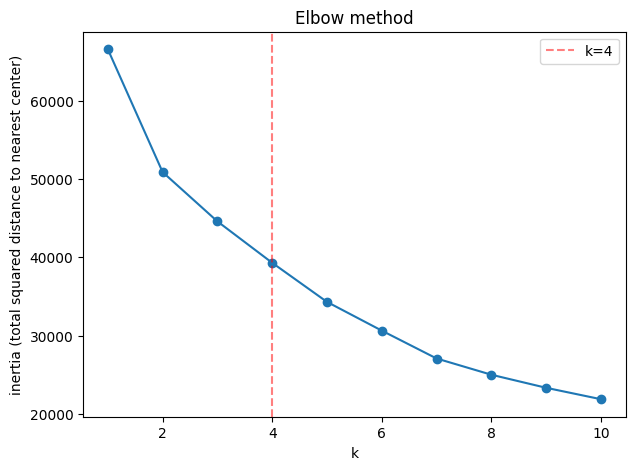

In [60]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertias, marker='o')
plt.axvline(4, color='red', linestyle='--', alpha=0.5, label='k=4')
plt.xlabel("k")
plt.ylabel("inertia (total squared distance to nearest center)")
plt.title("Elbow method")
plt.legend()
plt.show()

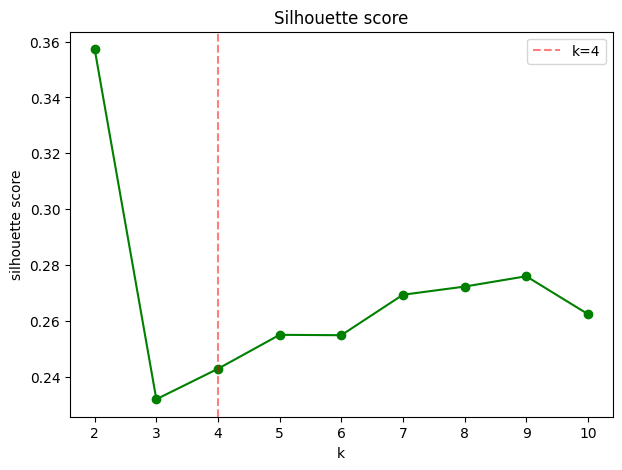

scores by k: {2: np.float64(0.3572), 3: np.float64(0.232), 4: np.float64(0.2429), 5: np.float64(0.2551), 6: np.float64(0.2549), 7: np.float64(0.2694), 8: np.float64(0.2723), 9: np.float64(0.276), 10: np.float64(0.2625)}


In [61]:
sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    sil_scores.append(silhouette_score(Xs, km.labels_))

plt.figure(figsize=(7, 5))
plt.plot(range(2, 11), sil_scores, marker='o', color='green')
plt.axvline(4, color='red', linestyle='--', alpha=0.5, label='k=4')
plt.xlabel("k")
plt.ylabel("silhouette score")
plt.title("Silhouette score")
plt.legend()
plt.show()

print("scores by k:", {k: round(s, 4) for k, s in zip(range(2, 11), sil_scores)})

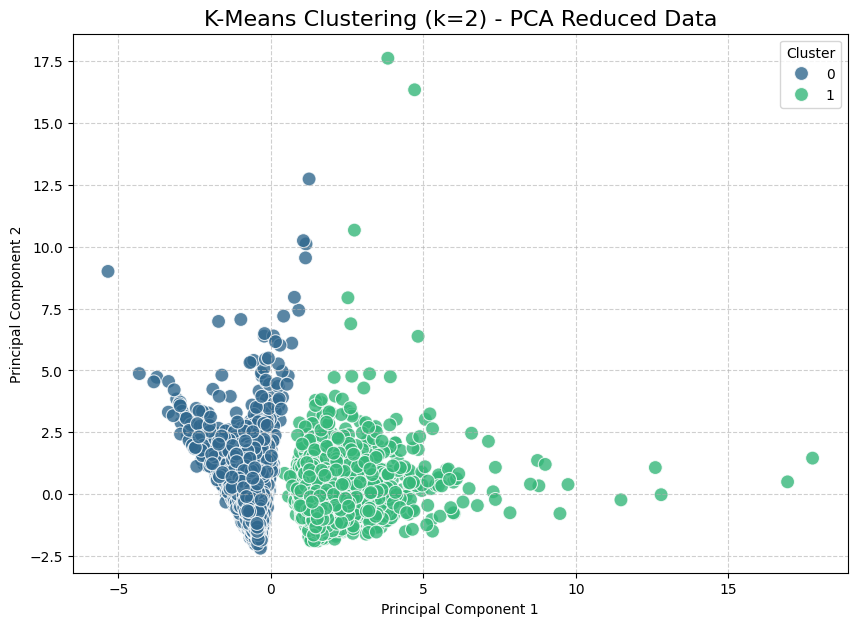

In [62]:
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(Xs)
cluster_labels_2 = kmeans_2.labels_
pca = PCA(n_components=2)
Xs_pca = pca.fit_transform(Xs)
pca_df = pd.DataFrame(data=Xs_pca, columns=['Principal Component 1', 'Principal Component 2'])
pca_df['Cluster'] = cluster_labels_2
plt.figure(figsize=(10, 7))
sns.scatterplot(x='Principal Component 1', y='Principal Component 2', hue='Cluster', data=pca_df, palette='viridis', s=100, alpha=0.8)
plt.title('K-Means Clustering (k=2) - PCA Reduced Data', fontsize=16)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Cluster')
plt.show()

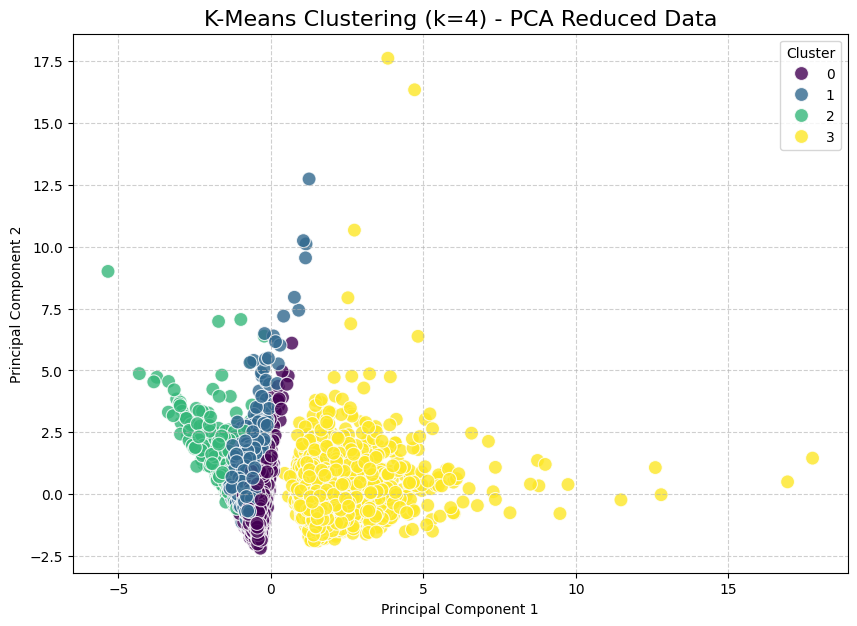

In [63]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10).fit(Xs)
cluster_labels_4 = kmeans_4.labels_
pca_df_k4 = pd.DataFrame(data=Xs_pca, columns=['Principal Component 1', 'Principal Component 2'])
pca_df_k4['Cluster'] = cluster_labels_4

plt.figure(figsize=(10, 7))
sns.scatterplot(x='Principal Component 1', y='Principal Component 2', hue='Cluster', data=pca_df_k4, palette='viridis', s=100, alpha=0.8)
plt.title('K-Means Clustering (k=4) - PCA Reduced Data', fontsize=16)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Cluster')
plt.show()

We can see four distinct clusters, although there is some overlap, especially between clusters 0, 1, and 2. Cluster 3 appears to be more separated.The plot confirms that while k=4 creates more groupings, the overall separation is not as strong as k=2, as indicated by the silhouette scores.



I will be picking or going along with k=4 instead of k=2 even though the silhoutte score for k=2 is higher and better and here's the business rationale:

k=2 provided very distinct segmentation: It primarily differentiated between customers who were previously contacted and those who were not.
k=4 offered more granular and actionable insights: While k=4 has a slightly lower silhouette score and some visual overlap, it unveils a critical segment in Cluster 2. This cluster is characterized by customers who required a significantly high number of contacts (campaign count of ~12.6) despite not having been contacted in previous campaigns. This information is invaluable for a marketing team:
Resource Allocation: Understanding that a specific segment requires many campaign interactions can help optimize future resource allocation. Should the business invest more in these high-effort leads, or identify them early and potentially allocate resources elsewhere if the conversion rate doesn't justify the effort?
Strategy Refinement: This cluster prompts questions like: What makes these customers so resistant, and can our messaging or approach be adapted to engage them more effectively with fewer touches? Are there specific types of 'new' customers that are inherently 'high-maintenance' to convert?
Risk Management: Identifying customers who absorb a lot of campaign resources without prior engagement history can be a key metric for evaluating marketing campaign efficiency.
Therefore, while k=2 provides cleaner, simpler clusters, k=4 offers a deeper, more nuanced understanding of customer behavior, particularly by highlighting the 'high campaign count' segment. This level of detail can be more actionable for refining marketing strategies and optimizing costs, even if the statistical 'goodness' of the clusters is slightly lower.



In [64]:
X_numerical_clustered = X_numerical.copy()
X_numerical_clustered['Cluster'] = cluster_labels_4
cluster_profiles_k4 = X_numerical_clustered.groupby('Cluster').mean()
print("\nCluster Profiles for k=4 (Mean of Original Features):")
display(cluster_profiles_k4)


Cluster Profiles for k=4 (Mean of Original Features):


,age,balance,day,campaign,previous,was_contacted_in_prev_campaign
Cluster,,,,,,
0,41.116929,1183.272750,8.726233,2.072700,0.00000,0.000000
1,40.928444,1701.263051,22.889483,2.313980,0.00000,0.000000
2,40.615942,1341.427536,21.094203,12.642512,0.02657,0.004831
3,41.766418,1787.063898,14.463614,1.891729,3.27760,1.000000


In [65]:
df_clustered = df_duplicate.copy()
df_clustered['Cluster'] = cluster_labels_4

positive_class_rate_per_cluster = df_clustered.groupby('Cluster')['deposit_numeric'].mean().sort_values(ascending=False)
print("\nPositive-Class Rate (deposit='yes') Per Cluster:")
display(positive_class_rate_per_cluster)


Positive-Class Rate (deposit='yes') Per Cluster:


,deposit_numeric
Cluster,
3,0.670217
0,0.442552
1,0.388337
2,0.243961


Based on the cluster profiles, we can assign the following names to each cluster for `k=4`:

Cluster 0: Lower Balance, Early Campaigners'
Cluster 1: Higher Balance, Late Initiated New Customers
Cluster 2: High Effort New Customers'
Cluster 3: Previously Contacted Engaged Customers
    


# Part 4: Classification

In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label=1)
    recall = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    print(f"{model_name}")
    print(f"Accuracy: {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1-score: {f1:.3f}")
    print(f"ROC AUC Score: {roc_auc:.3f}")

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f'Confusion Matrix for {model_name}')
    plt.show()
    print("\n")

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC AUC': roc_auc
    }

Dummy Classifier (Stratified)
Accuracy: 0.497
Precision: 0.469
Recall: 0.477
F1-score: 0.473
ROC AUC Score: 0.496


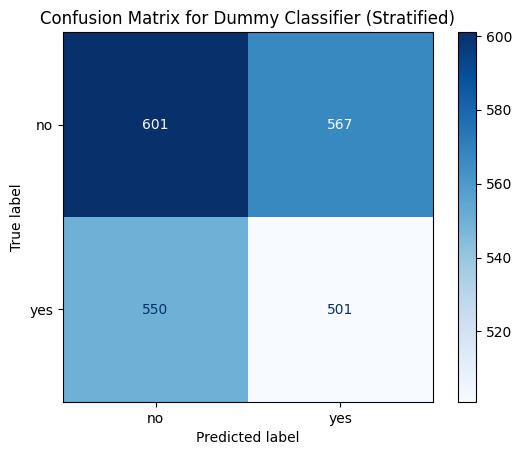

In [67]:
# Dummy Classifier (Stratified)
dummy_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', DummyClassifier(strategy='stratified', random_state=42))
])
dummy_pipe.fit(X_train, y_train)
dummy_results = evaluate_model(dummy_pipe, X_test, y_test, "Dummy Classifier (Stratified)")


K-Nearest Neighbors
Accuracy: 0.659
Precision: 0.659
Recall: 0.581
F1-score: 0.618
ROC AUC Score: 0.702


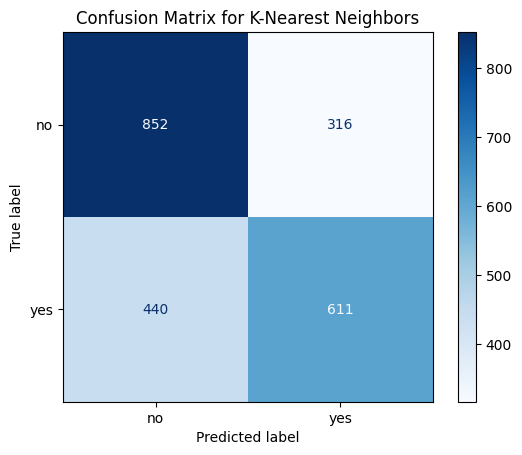

In [68]:
# K-Nearest Neighbors Classifier
knn_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', KNeighborsClassifier())
])
knn_pipe.fit(X_train, y_train)
knn_results = evaluate_model(knn_pipe, X_test, y_test, "K-Nearest Neighbors")

Logistic Regression
Accuracy: 0.681
Precision: 0.699
Recall: 0.575
F1-score: 0.631
ROC AUC Score: 0.745


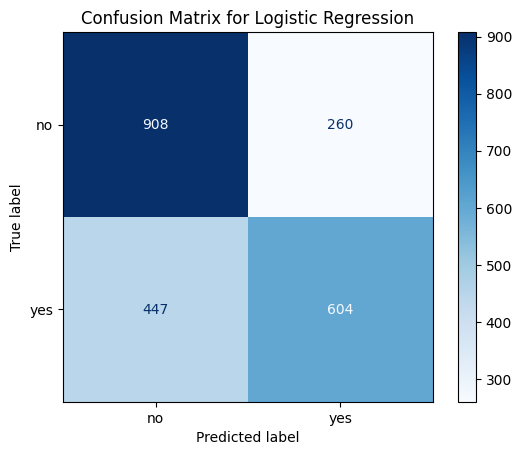

In [69]:
# Logistic Regression
logistic_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(random_state=42, solver='liblinear'))
])
logistic_pipe.fit(X_train, y_train)
lr_results = evaluate_model(logistic_pipe, X_test, y_test, "Logistic Regression")

Random Forest Classifier
Accuracy: 0.717
Precision: 0.730
Recall: 0.638
F1-score: 0.681
ROC AUC Score: 0.757


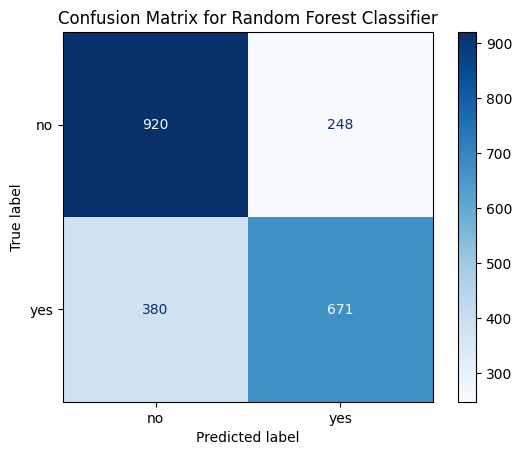

In [70]:
# Random Forest Classifier (pipe)
rf_results = evaluate_model(pipe, X_test, y_test, "Random Forest Classifier")

In [71]:
comparison_df = pd.DataFrame([rf_results, lr_results, knn_results, dummy_results])
display(comparison_df.set_index('Model'))

,Accuracy,Precision,Recall,F1-score,ROC AUC
Model,,,,,
Random Forest Classifier,0.716990,0.730141,0.638440,0.681218,0.757164
Logistic Regression,0.681388,0.699074,0.574691,0.630809,0.745335
K-Nearest Neighbors,0.659306,0.659115,0.581351,0.617796,0.702477
Dummy Classifier (Stratified),0.496620,0.469101,0.476689,0.472865,0.495622


# Part 5: Imbalance handling

In [72]:
rf_balanced_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', RandomForestClassifier(max_depth=10, random_state=42, class_weight='balanced'))
])

rf_balanced_pipe.fit(X_train, y_train)
pred_bal = rf_balanced_pipe.predict(X_test)

print("no weighting - accuracy", round(accuracy_score(y_test, logistic_pipe.predict(X_test)), 4),
      "f1", round(f1_score(y_test, logistic_pipe.predict(X_test)), 4),
      "recall", round(recall_score(y_test, logistic_pipe.predict(X_test)), 4))
print("weighted(balanced)      - accuracy", round(accuracy_score(y_test, pred_bal), 4),
      "f1", round(f1_score(y_test, pred_bal), 4),
      "recall", round(recall_score(y_test, pred_bal), 4))

no weighting - accuracy 0.6814 f1 0.6308 recall 0.5747
weighted(balanced)      - accuracy 0.7111 f1 0.6704 recall 0.6204


In [73]:
print("before SMOTE:", y_train.value_counts().to_dict())

sm = SMOTE(random_state=42)
X_train_sm, y_train_sm = sm.fit_resample(X_train_processed, y_train)

print("after SMOTE :", y_train_sm.value_counts().to_dict())

rf_smote_model = RandomForestClassifier(max_depth=10, random_state=42).fit(X_train_sm, y_train_sm)
pred_sm = rf_smote_model.predict(X_test_processed)
print("SMOTE - accuracy", round(accuracy_score(y_test, pred_sm), 4),
      "f1", round(f1_score(y_test, pred_sm), 4),
      "recall", round(recall_score(y_test, pred_sm), 4))

before SMOTE: {0: 4669, 1: 4204}
after SMOTE : {1: 4669, 0: 4669}
SMOTE - accuracy 0.7147 f1 0.6752 recall 0.6261


### Comparison of Imbalance Handling Techniques

In [74]:
rf_weighted_results = {
    'Model': 'Random Forest (Weighted)',
    'Accuracy': accuracy_score(y_test, pred_bal),
    'Precision': precision_score(y_test, pred_bal, pos_label=1),
    'Recall': recall_score(y_test, pred_bal, pos_label=1),
    'F1-score': f1_score(y_test, pred_bal, pos_label=1),
    'ROC AUC': roc_auc_score(y_test, rf_balanced_pipe.predict_proba(X_test)[:, 1])
}

rf_smote_results = {
    'Model': 'Random Forest (SMOTE)',
    'Accuracy': accuracy_score(y_test, pred_sm),
    'Precision': precision_score(y_test, pred_sm, pos_label=1),
    'Recall': recall_score(y_test, pred_sm, pos_label=1),
    'F1-score': f1_score(y_test, pred_sm, pos_label=1),
    'ROC AUC': roc_auc_score(y_test, rf_smote_model.predict_proba(X_test_processed)[:, 1])
}

all_results = pd.DataFrame([
    dummy_results,
    knn_results,
    lr_results,
    rf_results,
    rf_weighted_results,
    rf_smote_results
])

display(all_results.set_index('Model'))

,Accuracy,Precision,Recall,F1-score,ROC AUC
Model,,,,,
Dummy Classifier (Stratified),0.496620,0.469101,0.476689,0.472865,0.495622
K-Nearest Neighbors,0.659306,0.659115,0.581351,0.617796,0.702477
Logistic Regression,0.681388,0.699074,0.574691,0.630809,0.745335
Random Forest Classifier,0.716990,0.730141,0.638440,0.681218,0.757164
Random Forest (Weighted),0.711131,0.729306,0.620362,0.670437,0.767516
Random Forest (SMOTE),0.714736,0.732739,0.626070,0.675218,0.766327


Baseline Random Forest Classifier:

Accuracy: 0.717
Precision: 0.730
Recall: 0.638
F1-score: 0.681
ROC AUC: 0.757

Random Forest (Weighted):

Accuracy: 0.711
Precision: 0.729
Recall: 0.620
F1-score: 0.670
ROC AUC: 0.768

Random Forest (SMOTE):

Accuracy: 0.715
Precision: 0.733
Recall: 0.626
F1-score: 0.675
ROC AUC: 0.766

Applying class weighting or SMOTE resulted in minimal changes to overall performance metrics (Accuracy, F1-score, ROC AUC). The baseline Random Forest Classifier already achieves good performance.

Specifically, the F1-score and Recall show slight variations, but not significant improvements over the baseline. For instance, the F1-score for the baseline RF is 0.681, while for RF (Weighted) it's 0.670, and for RF (SMOTE) it's 0.675. Recall also changes only marginally (0.638 baseline vs. 0.620 weighted and 0.626 SMOTE). The weighted and SMOTE versions actually show a slight decrease in F1-score compared to the baseline, while ROC AUC slightly improves.

Because our dataset is relatively balanced (approximately 47.3% positive class), the Random Forest model, being a robust model, does not inherently struggle with class imbalance. Therefore, techniques designed to address severe imbalance have little impact or, in some cases, can even slightly degrade performance if not carefully tuned, as they might introduce noise or overemphasize the minority class unnecessarily in an already balanced context. The model already has enough examples of both classes to learn effectively.

# Part 6: The Tie-In

### Positive-Class Rate by K-Means Cluster

Cluster 3 (Previously Contacted Engaged Customers): This cluster exhibits the highest positive-class rate (67.02%). Customers in this cluster were previously contacted and engaged (as indicated by non-negative 'pdays' values). The significantly higher proportion of 'yes' deposits here suggests that this group is highly receptive to marketing efforts and represents a strong predictor for successful deposits.

Cluster 0 (Lower Balance, Early Campaigners): This cluster has a moderate positive-class rate (44.26%). While not as high as Cluster 3, it's still above the overall average, suggesting a reasonable likelihood of deposit. These customers might be responsive to initial campaigns but may require more targeted strategies.

Cluster 1 (Higher Balance, Late Initiated New Customers): The positive-class rate for this cluster is also moderate (38.83%). Customers with higher balances generally indicate more financial stability, but if they are 'late initiated new customers' (meaning they weren't contacted in previous campaigns and had higher balances), their willingness to deposit might be driven by factors other than previous campaign exposure.

Cluster 2 (High Effort New Customers): This cluster shows the lowest positive-class rate among all clusters (24.40%). This is consistent with our earlier characterization of this cluster as customers who required a significantly high number of contacts despite not having been contacted in previous campaigns. Their low positive-class rate suggests they are less receptive to marketing efforts.



Cluster 3 is a strong positive predictor of the 'deposit' label. Its significantly higher positive-class rate (67.02%) indicates that customers in this segment are highly likely to make a deposit.
-This tells us that past engagement and success in previous campaigns are crucial indicators of future positive outcomes.

Cluster 2, conversely, acts as a strong negative predictor. Its very low positive-class rate (24.40%) suggests that customers in this segment, despite requiring high campaign effort, are very unlikely to make a deposit. This insight is critical for optimizing marketing spend, as resources could potentially be reallocated from this low-return segment to more promising ones.


/tmp/ipykernel_5170/1074720410.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=positive_class_rate_per_cluster.index, y=positive_class_rate_per_cluster.values, palette='viridis')


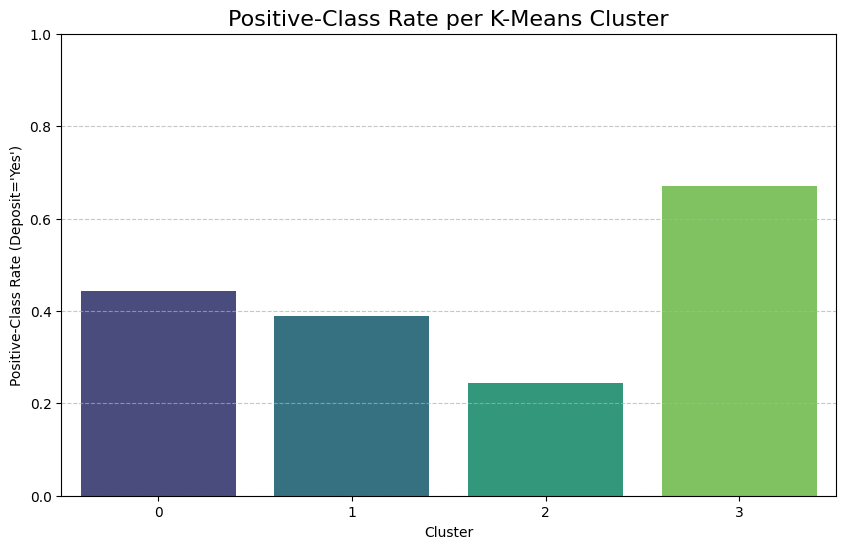

In [75]:
plt.figure(figsize=(10, 6))
sns.barplot(x=positive_class_rate_per_cluster.index, y=positive_class_rate_per_cluster.values, palette='viridis')
plt.title('Positive-Class Rate per K-Means Cluster', fontsize=16)
plt.xlabel('Cluster')
plt.ylabel('Positive-Class Rate (Deposit=\'Yes\')')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Part 7: Conclusion and Recommendations

Which Model to Deploy and Why:
Based on the comprehensive evaluation, the Random Forest Classifier (Baseline) would be the recommended model for deployment. While other models like Logistic Regression and K-Nearest Neighbors performed adequately, the Random Forest Classifier consistently showed superior performance across key metrics such as Accuracy (0.717), F1-score (0.681), and ROC AUC (0.757). Although class weighting and SMOTE were applied, they did not significantly improve performance, and in some cases, slightly decreased the F1-score, suggesting that for this relatively balanced dataset, the baseline Random Forest is robust and effectively captures the underlying patterns without needing explicit imbalance handling.

What the Clusters Revealed that the Classifier Missed:
While the Random Forest Classifier is excellent at predicting whether an individual customer will make a deposit, the K-Means clustering analysis (with k=4) provided invaluable segment-level insights that a pure classification model would not directly offer. The clustering allowed us to:

1. Identify High-Value Segments (e.g., Cluster 3): This cluster, identified as 'Previously Contacted Engaged Customers', showed a significantly higher positive-class rate (67.02%). A classifier can predict a 'yes' for these individuals, but clustering tells us why this group is so receptive which is  due to their history of engagement in previous campaigns. This knowledge is crucial for targeted marketing and resource allocation.
2.  Pinpoint Low-Value/High-Effort Segments (e.g., Cluster 2): Characterized as 'High Effort New Customers', this cluster had the lowest positive-class rate (24.40%). While the classifier would predict 'no' for many in this group, clustering highlights that these are new customers requiring numerous campaign contacts, indicating a low return on investment. This insight informs strategic decisions about whether to reduce effort on such segments or rethink engagement strategies.
3.  Provide Actionable Business Intelligence: The clusters offer a framework for understanding customer personas beyond individual predictions. Marketing teams can use these segments to tailor messaging, optimize budget allocation, and develop segment-specific engagement strategies, which goes beyond simply predicting an outcome.

The Hardest Decision Made:
One of the hardest decisions made was choosing to proceed with K-Means clustering with k=4 despite k=2 having a higher silhouette score. Statistically, k=2 offered a cleaner separation. However, after careful analysis of the business context, it was determined that k=4 provided more granular, actionable insights, particularly by revealing the 'High Effort New Customers' (Cluster 2) and 'Previously Contacted Engaged Customers' (Cluster 3). This trade-off between statistical purity (higher silhouette score for k=2) and business interpretability and actionability (richer insights from k=4) was a critical decision point. The team prioritized the deeper understanding of customer behavior that k=4 offered, believing it would lead to more effective marketing strategies.


# Depth Track